Libraries imported successfully!

Dataset loaded successfully!
Number of samples: 1797
Number of pixel features: 64
Number of true digit classes: 10

K-MEANS CLUSTERING EVALUATION
------------------------------------------------
K (Clusters)   | Inertia        | Silhouette  
------------------------------------------------
2              | 100423.84      | 0.1056      
3              | 93842.48       | 0.1053      
4              | 89213.97       | 0.0954      
5              | 85096.05       | 0.1023      
6              | 81678.47       | 0.0988      
7              | 77749.33       | 0.1135      
8              | 74854.16       | 0.1266      
9              | 72029.73       | 0.1360      
10             | 69813.56       | 0.1394      
11             | 67261.85       | 0.1532      
12             | 65031.72       | 0.1543      
13             | 62763.18       | 0.1565      
14             | 61963.42       | 0.1562      
15             | 59534.50       | 0.1583      
16             | 

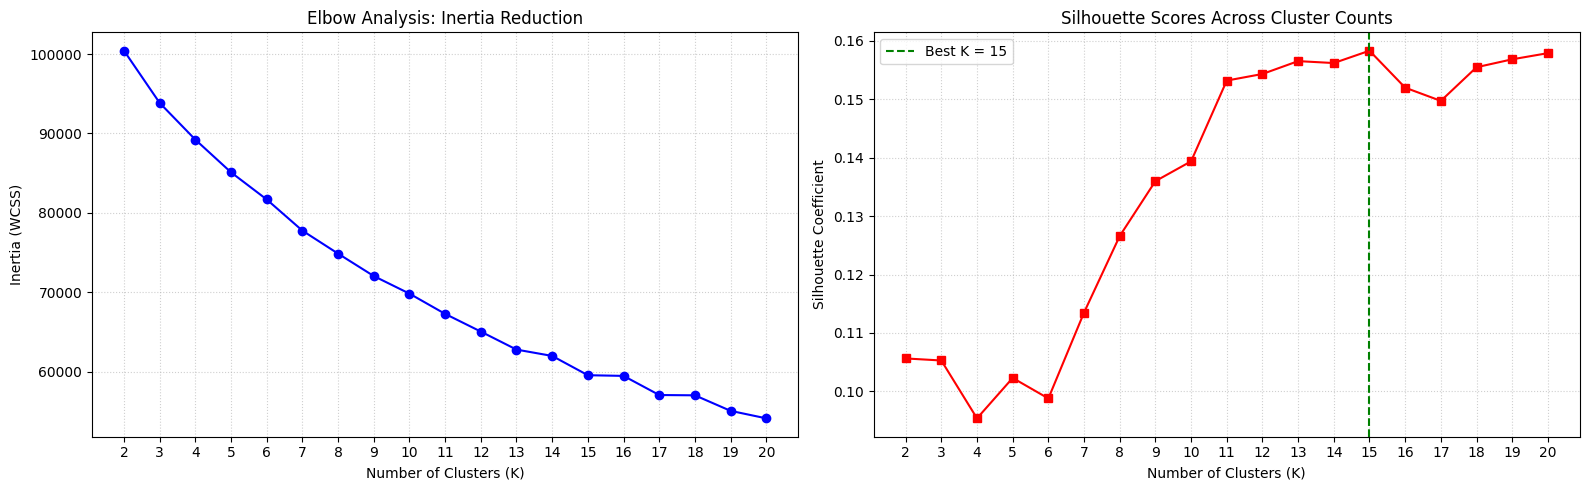


K = 10 clustering completed!
Inertia: 69813.56
Silhouette score: 0.1394


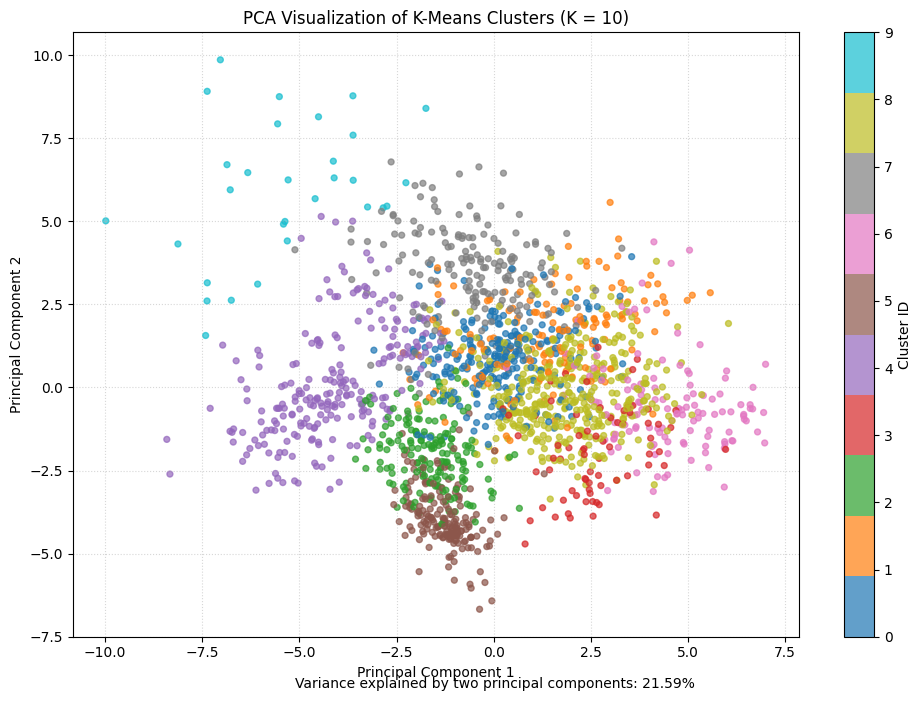


ADJUSTED RAND INDEX (ARI) COMPARISON
-----------------------------------
K          | ARI Score   
-----------------------------------
2          | 0.1266
3          | 0.2232
4          | 0.2969
5          | 0.2942
6          | 0.3590
7          | 0.3825
8          | 0.4687
9          | 0.4620
10         | 0.5344
11         | 0.5421
12         | 0.5512
13         | 0.5506
14         | 0.5669
15         | 0.5683
16         | 0.6109
17         | 0.6406
18         | 0.5241
19         | 0.6328
20         | 0.6397

Best K according to ARI: 17
Highest ARI score: 0.6406


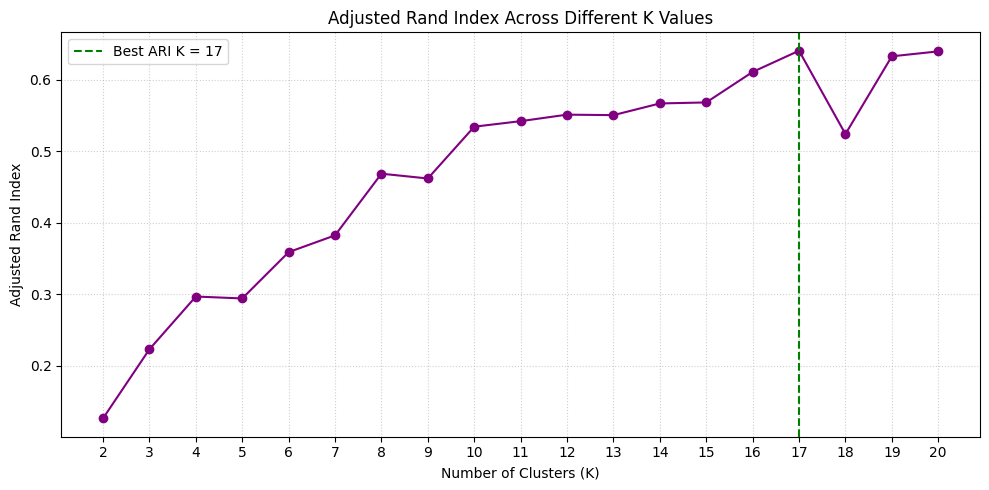

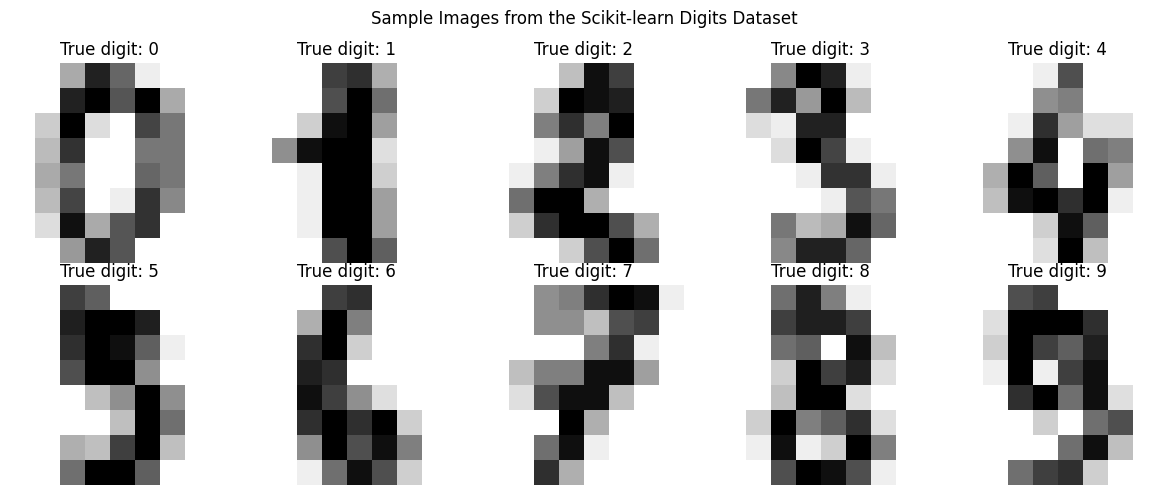


Analysis completed successfully!


In [ ]:
# ============================================================
# HANDWRITTEN DIGITS CLUSTERING ANALYSIS USING K-MEANS
# Google Colab - Complete Runnable Code
# ============================================================

# 1. IMPORT REQUIRED LIBRARIES
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

# ============================================================
# 2. LOAD AND PREPROCESS THE DIGITS DATASET
# ============================================================

digits = load_digits()

X = digits.data
y = digits.target

# Standardize pixel features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nDataset loaded successfully!")
print(f"Number of samples: {X.shape[0]}")
print(f"Number of pixel features: {X.shape[1]}")
print(f"Number of true digit classes: {len(np.unique(y))}")

# ============================================================
# 3. ITERATIVE GRID SCAN FOR K = 2 TO 20
# ============================================================

cluster_range = range(2, 21)

inertia_scores = []
silhouette_scores = []

print("\nK-MEANS CLUSTERING EVALUATION")
print("-" * 48)
print(f"{'K (Clusters)':<14} | {'Inertia':<14} | {'Silhouette':<12}")
print("-" * 48)

for k in cluster_range:

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_scaled, cluster_labels)

    inertia_scores.append(inertia)
    silhouette_scores.append(silhouette)

    print(f"{k:<14} | {inertia:<14.2f} | {silhouette:<12.4f}")

# Identify the best K according to silhouette score
best_index = np.argmax(silhouette_scores)
best_k = list(cluster_range)[best_index]
best_silhouette = silhouette_scores[best_index]

print("\nBest K according to silhouette score:", best_k)
print(f"Best silhouette score: {best_silhouette:.4f}")

# ============================================================
# 4. VISUALIZE ELBOW AND SILHOUETTE SCORES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow method: inertia
axes[0].plot(
    list(cluster_range),
    inertia_scores,
    marker="o",
    color="blue",
    linestyle="-"
)

axes[0].set_title("Elbow Analysis: Inertia Reduction")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(list(cluster_range))
axes[0].grid(True, linestyle=":", alpha=0.6)

# Silhouette score
axes[1].plot(
    list(cluster_range),
    silhouette_scores,
    marker="s",
    color="red",
    linestyle="-"
)

axes[1].axvline(
    best_k,
    color="green",
    linestyle="--",
    label=f"Best K = {best_k}"
)

axes[1].set_title("Silhouette Scores Across Cluster Counts")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Coefficient")
axes[1].set_xticks(list(cluster_range))
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ============================================================
# 5. K-MEANS CLUSTERING WITH K = 10
# ============================================================

optimal_k = 10

kmeans_optimal = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)

optimal_labels = kmeans_optimal.fit_predict(X_scaled)

print("\nK = 10 clustering completed!")
print("Inertia:", round(kmeans_optimal.inertia_, 2))
print(
    "Silhouette score:",
    round(silhouette_score(X_scaled, optimal_labels), 4)
)

# ============================================================
# 6. PCA DIMENSIONALITY REDUCTION AND CLUSTER VISUALIZATION
# ============================================================

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = np.sum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=optimal_labels,
    cmap="tab10",
    alpha=0.7,
    s=18
)

plt.colorbar(scatter, label="Cluster ID")
plt.title("PCA Visualization of K-Means Clusters (K = 10)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle=":", alpha=0.5)

plt.figtext(
    0.5, 0.01,
    f"Variance explained by two principal components: "
    f"{explained_variance:.2f}%",
    ha="center"
)

plt.tight_layout()
plt.show()

# ============================================================
# 7. EVALUATE CLUSTER AGREEMENT WITH TRUE DIGIT LABELS
# ============================================================

print("\nADJUSTED RAND INDEX (ARI) COMPARISON")
print("-" * 35)
print(f"{'K':<10} | {'ARI Score':<12}")
print("-" * 35)

ari_scores = []

for k in cluster_range:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    predicted_labels = model.fit_predict(X_scaled)
    ari = adjusted_rand_score(y, predicted_labels)

    ari_scores.append(ari)

    print(f"{k:<10} | {ari:.4f}")

best_ari_index = np.argmax(ari_scores)
best_ari_k = list(cluster_range)[best_ari_index]

print("\nBest K according to ARI:", best_ari_k)
print(f"Highest ARI score: {ari_scores[best_ari_index]:.4f}")

# Plot ARI scores
plt.figure(figsize=(10, 5))

plt.plot(
    list(cluster_range),
    ari_scores,
    marker="o",
    color="purple"
)

plt.axvline(
    best_ari_k,
    color="green",
    linestyle="--",
    label=f"Best ARI K = {best_ari_k}"
)

plt.title("Adjusted Rand Index Across Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Adjusted Rand Index")
plt.xticks(list(cluster_range))
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ============================================================
# 8. DISPLAY SAMPLE HANDWRITTEN DIGITS
# ============================================================

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"True digit: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Images from the Scikit-learn Digits Dataset")
plt.tight_layout()
plt.show()

# ============================================================
# END OF ANALYSIS
# ============================================================

print("\nAnalysis completed successfully!")